# Cifar-10 CNN model

Cifar-10 convolutional neural network (CNN) implementation using `Keras` module of the `TensorFlow` library. Keras provides the models and layers used in this classification task.

Import `TensorFlow` as backend before importing the `Keras` library.
Import `Time` to measure the training speed and `matplotlib.pyplot` for visualisation.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras import backend as K

import time

import numpy as np
import matplotlib.pyplot as plt

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Load the Cifar-10 dataset from the keras module. The data fetched is already divided into training and validation datasets. 

The data contains 10 different classes of color images of size 32x32. The classes are: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. 

The training set includes 50 000 images and test set 10 000 images. 

In [2]:
keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

print(x_train.shape)

(50000, 32, 32, 3)


The output of the shape shows the number of images (50000), the image size as height and width (32x32) and the RGB format (3) since the images are colored.

For visualization, display a 5x5 grid of the sample images from the training set labeled with its corresponding class name.

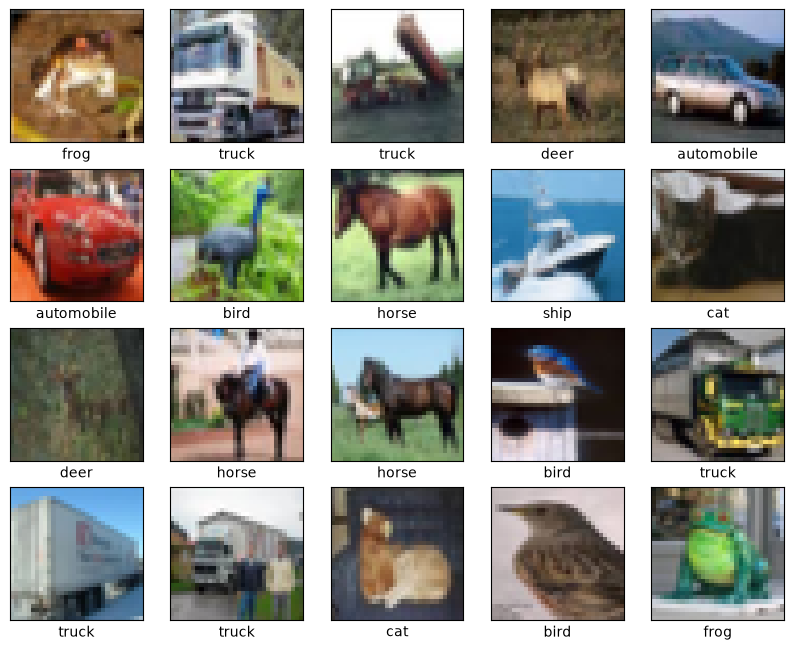

In [4]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(20):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    # The CIFAR labels happen to be arrays, 
    # which is why need the extra index
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

Before building and training the model, the images are normalized. Since the pixel range of color image is 0-255, each pixel should be divided by 255. Now, the pixel values of each image range from 0-1.

In [3]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

Next the model architecture will be defined. The model is built using the `Sequental API` provided by Keras.

JATKUUU

In [5]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dropout(0.5),
    #layers.Dense(64, activation='relu'),
    layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,626 (420.41 KB)

 Trainable params: 107,626 (420.41 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
## Nur
## Suorituskykyä (tarkkuus testidatalla)
## Oppimiskäyrää (training vs. validation loss)


In [7]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [ ]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)

t0 = time.time()

history = model.fit(x_train, y_train, epochs=50, batch_size=64,
                    validation_split=0.1, callbacks=[callback], verbose=2)

train_time = time.time() - t0
print(f"Opetusaika: {train_time:.1f} s")

Epoch 1/50
704/704 - 27s - 38ms/step - accuracy: 0.3330 - loss: 1.7818 - val_accuracy: 0.5006 - val_loss: 1.3786
Epoch 2/50
704/704 - 27s - 38ms/step - accuracy: 0.4828 - loss: 1.4291 - val_accuracy: 0.5522 - val_loss: 1.2252
Epoch 3/50
704/704 - 28s - 40ms/step - accuracy: 0.5399 - loss: 1.2855 - val_accuracy: 0.5782 - val_loss: 1.1560
Epoch 4/50
704/704 - 39s - 55ms/step - accuracy: 0.5754 - loss: 1.1891 - val_accuracy: 0.6466 - val_loss: 1.0096
Epoch 5/50
704/704 - 26s - 37ms/step - accuracy: 0.6064 - loss: 1.1173 - val_accuracy: 0.6738 - val_loss: 0.9096
Epoch 6/50
704/704 - 29s - 42ms/step - accuracy: 0.6222 - loss: 1.0674 - val_accuracy: 0.6902 - val_loss: 0.8761
Epoch 7/50
704/704 - 26s - 37ms/step - accuracy: 0.6422 - loss: 1.0243 - val_accuracy: 0.7110 - val_loss: 0.8313
Epoch 8/50
704/704 - 26s - 37ms/step - accuracy: 0.6527 - loss: 0.9871 - val_accuracy: 0.7274 - val_loss: 0.7884
Epoch 9/50


In [ ]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.grid()
plt.show()

In [ ]:
test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

In [ ]:
## Sandra : Visualisoi tuloksia:

#Näytä esimerkkikuvia ja mallien luokittelutuloksia
#Esitä luokkien todennäköisyysjakaumia
#Analysoi väärin luokiteltuja kuvia

In [ ]:
x = x_test
y = model(x)
start = 2000

for k in range(10):
    plt.figure(figsize=(7, 3))
    
    plt.subplot(1,2,1)
    plt.imshow(x[start+k])

    
    plt.subplot(1,2,2)
    plt.bar(class_names, y[start+k].numpy().flatten())
    plt.xticks(rotation=45, ha="right")
    
    plt.ylabel("Probability")
    plt.title("Model Prediction")
    plt.tight_layout()
    plt.show()

Analysoi väärin luokiteltuja kuvia: Taustaväri vaikuttaa: esim jos tausta on sininen malli sekoittaa: laiva tai lentokone, jos on vihreä tausta malli sekoittaa: hevonen.   jos on kissa tai koira malli sekoittaa, ei ole varma mikä eläin. 

## Test results and conclusions (Riikka)

In order to improve the performance of the model, multiple different versions were tested. The goal was to increase the accuracy score while decreasing the test loss score. The training and validation accuracy and loss scores as well as the training time were also analyzed for the different versions. Since the tests were performed on one device the results might change if the tests are performed again. Different devices might require a lot more time to train the models. For example, while the final version of the model took around 10 minutes to train on one device, on another device it took around 20 minutes.

The table below shows the different versions that were tested, their accuracy and test loss scores, training time and conclusion about the tested version.

| Test            | Modification                                                                | Accuracy (%) | Test loss |  Training time (s) | Conclusion            |
| --------------- | --------------------------------------------------------------------------- | ------------ | --------- | ------------------ | --------------------- |
| Original model  |                                                                             | 69. 8        | 0.890     | 114.7              |The model accurately classifies over half of the pictures. The training loss values did decrease evenly but the validation loss values did not seem get better after the first four epochs. The curves did not curve downwards at an even pace.                |
| Version 1       | Added Dropout(0.5)                                                          | 74.2        | 0.757     | 195.2              |The test accuracy and test loss scores are better than in the original version but the training time is longer. The training loss and validation loss values increase evenly. |
| Version 2       | Added BatchNormalization() after first conv layer                           | 71.0        | 0.839     | 171.9               |The test accuracy and test loss scores are worse than in the previous version while training time was faster. The training loss values did decrease evenly but validation loss scores did not decrease much after the nineth epoch and started to fluctuate more. |
| Version 3       | Removed BatchNormalization(), added RandomFlip('horizontal') and RandomTranslation(0.1, 0.1)| 74.6        | 0.737     | 264.88               |The test accuracy and test loss scores are slightly better than in the previous versions but the training time is longer. The training loss and validation loss values decreased evenly and validation loss values seem to be better than the training loss values, and they fluctuate less in the later epochs. The model seems to learn better than in the previous versions.                |
| Version 4       | Added Conv2D(32)                                                            | 78.4        | 0.635     | 649.3               |The test accuracy and test loss scores are better than in the previous versions but the training time over double the time it was the previous version. The training loss and validation loss values decreased evenly and validation loss values seem to be better than the training loss values.                |

Below are the different versions of the model that were tested. The versions are shown in their code format to show the placement of the added layers. The "Added layers" spefication under the version specifies which layers were added on to the original model.


**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dense(10, activation="softmax"),
])
```

**Version 1**<br>
**Added layers: Dropout(0.5)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
```

**Version 2**<br>
**Added layers: BatchNormalization(), Dropout(0.5)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
```

**Version 3**<br>
**Added layers: RandomFlip("horizontal"), RandomTranslation(0.1, 0.1), Dropout(0.5)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
```

**Version 4**<br>
**Added layers: Conv2D(32, kernel_size=3, activation="relu"), RandomFlip("horizontal"), RandomTranslation(0.1, 0.1), Dropout(0.5)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),      
    
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
```

Version 4 was chosen as the final model. It has the best performance of all the models though it is also the slowest to train. The accuracy score is aproximately 78% which is a lot higher than the original version's score. The additional Conv2D layer seems to increase the training time a lot which makes sense since the model scans the created tensor again using 32 different kernels to create a new tensor. 

The neural network could be improved to get better results althought this might also make the model slower to train. The model's accuracy is already quite good considering that the images are quite low quality sometimes making it hard to identify the target even for human eyes.

## FCN and CNN model comparison

The two models are quite different in both the performance and structure. In this section the perfromance and structure of the models are compared. Performance comparison is done by analysing the accuracy and loss scores of the training, validation and test phases as well as the training time. Structure comparison is done by analysing the structures of the neural networks including the number of parameteres.

### Performance comparison

The final version of the FCN model has an test accuracy score of around 53% and the final version of the CNN model test accuracy score is around 78%. Logically, the test loss score of the CNN model is also better than the FCN model's. The CNN model is way better at identifying the targets in the images. On the other hand, the CNN model is way slower to train. Predictions do take slightly more time to make but it is not that concerning. During training the validation loss values and the curve seem to fluctuate a lot with the FCN model and the validation loss values are not better than the training loss values. The CNN model's validation loss values and curve are more stable and the validation loss values seem to be better than the training loss values. The CNN model seems to be better at learning than the FCN model.

### Structure comparison

The models have an input layer and an outputlayer as well as some additional hidden layers. The final version of the FCN model has seven additional layers. The final version CNN model has 11 additional layers. The FCN model has a total of 1,740,938 parameters with 1,739,914 of them being trainable, while the CNN model has a total of 107,626 parameters and they are all trainable. The FCN model has a lot more parameters to train than the CNN model though the CNN model might look more complex on the surface.

### Conclusion

The CNN model is better at handling image data than the FCN model. CNN models treat image inputs as multidimensional and while FCN models fletten the images into one-dimensional arrays. CNN models can keep track of the spatial locations of the features due to the multidimensional data handling and the can find similar features from different areas of the image while scanning through the image using a kernel. FCN models cannot deduce which inputs or pixels are next to each other and as such it need to learn the feature for each part of the image, meaning they have to individually learn similar features for different areas of the image and if the target is angled slightly differently the learning needs to be repeated. 

Overall, the CNN model is better for this task as it is noticeably more accurate than the FCN model. The training does take more time but actual predictio nmaking is not much slower than wiht the FCN model. 